In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc")

print("Path to dataset files:", path)

100%|██████████| 14.4M/14.4M [00:02<00:00, 6.51MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2


In [ ]:
# ============================================================
# STEP 2: Inspect downloaded dataset files
# Purpose:
# We are checking which files are present inside the GDSC dataset folder.
# This helps us identify the main CSV/Excel files needed for analysis.
# ============================================================

import os
import pandas as pd

# Print all files inside the downloaded dataset folder
print("Dataset path:", path)
print("\nFiles available in dataset folder:\n")

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

Dataset path: /root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2

Files available in dataset folder:

/root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2/Cell_Lines_Details.xlsx
/root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2/Compounds-annotation.csv
/root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2/GDSC_DATASET.csv
/root/.cache/kagglehub/datasets/samiraalipour/genomics-of-drug-sensitivity-in-cancer-gdsc/versions/2/GDSC2-dataset.csv


In [ ]:
# ============================================================
# STEP 3: Load and inspect the GDSC dataset
# Purpose:
# In this step, we load the main GDSC dataset and check its
# structure before preprocessing and model development.
# ============================================================

import os
import pandas as pd

# ------------------------------------------------------------
# 3.1 Define file path
# ------------------------------------------------------------

dataset_file = os.path.join(
    path,
    "GDSC_DATASET.csv"
)

# ------------------------------------------------------------
# 3.2 Load dataset
# ------------------------------------------------------------

df = pd.read_csv(dataset_file)

# ------------------------------------------------------------
# 3.3 Basic dataset information
# ------------------------------------------------------------

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
for col in df.columns:
    print(col)

# ------------------------------------------------------------
# 3.4 Display first rows
# ------------------------------------------------------------

print("\nFirst 5 rows:")
df.head()

Dataset loaded successfully.
Dataset shape: (242035, 19)

Column names:
COSMIC_ID
CELL_LINE_NAME
TCGA_DESC
DRUG_ID
DRUG_NAME
LN_IC50
AUC
Z_SCORE
GDSC Tissue descriptor 1
GDSC Tissue descriptor 2
Cancer Type (matching TCGA label)
Microsatellite instability Status (MSI)
Screen Medium
Growth Properties
CNA
Gene Expression
Methylation
TARGET
TARGET_PATHWAY

First 5 rows:


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication


In [ ]:
# ============================================================
# STEP 3B: Check missing values and data types
# Purpose:
# We check missing values and column data types to decide
# which preprocessing steps are required.
# ============================================================

print("Data types:")
print(df.dtypes)

print("\nMissing values per column:")
missing_values = df.isnull().sum().sort_values(ascending=False)
print(missing_values)

print("\nMissing value percentage:")
missing_percentage = (df.isnull().mean() * 100).sort_values(ascending=False)
print(missing_percentage)

Data types:
COSMIC_ID                                    int64
CELL_LINE_NAME                              object
TCGA_DESC                                   object
DRUG_ID                                      int64
DRUG_NAME                                   object
LN_IC50                                    float64
AUC                                        float64
Z_SCORE                                    float64
GDSC Tissue descriptor 1                    object
GDSC Tissue descriptor 2                    object
Cancer Type (matching TCGA label)           object
Microsatellite instability Status (MSI)     object
Screen Medium                               object
Growth Properties                           object
CNA                                         object
Gene Expression                             object
Methylation                                 object
TARGET                                      object
TARGET_PATHWAY                              object
dtype: object

Miss

In [ ]:
# ============================================================
# STEP 4: Data cleaning and target generation
# Purpose:
# In this step, we clean the dataset and create the primary
# prediction target: Drug Sensitivity / Resistance.
#
# Primary target:
# - Sensitive
# - Resistant
#
# Rule:
# Lower LN_IC50 means stronger drug sensitivity.
# Higher LN_IC50 means drug resistance.
# We use the median LN_IC50 as the threshold.
# ============================================================

import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 4.1 Create a working copy of the dataset
# ------------------------------------------------------------

data = df.copy()

print("Original dataset shape:", data.shape)

# ------------------------------------------------------------
# 4.2 Keep only relevant columns for ML analysis
# ------------------------------------------------------------

selected_columns = [
    "COSMIC_ID",
    "CELL_LINE_NAME",
    "TCGA_DESC",
    "DRUG_ID",
    "DRUG_NAME",
    "LN_IC50",
    "AUC",
    "Z_SCORE",
    "GDSC Tissue descriptor 1",
    "GDSC Tissue descriptor 2",
    "Cancer Type (matching TCGA label)",
    "Microsatellite instability Status (MSI)",
    "Screen Medium",
    "Growth Properties",
    "CNA",
    "Gene Expression",
    "Methylation",
    "TARGET",
    "TARGET_PATHWAY"
]

data = data[selected_columns]

# ------------------------------------------------------------
# 4.3 Fill missing categorical values
# Purpose:
# Most missing values are categorical, so we replace them with
# "Unknown" instead of deleting many useful samples.
# ------------------------------------------------------------

categorical_columns = data.select_dtypes(include=["object"]).columns

for col in categorical_columns:
    data[col] = data[col].fillna("Unknown")

# ------------------------------------------------------------
# 4.4 Check numerical missing values
# Purpose:
# LN_IC50, AUC, and Z_SCORE are important numerical response
# columns. If any missing values exist, remove those rows.
# ------------------------------------------------------------

numeric_columns = ["LN_IC50", "AUC", "Z_SCORE"]

data = data.dropna(subset=numeric_columns)

# ------------------------------------------------------------
# 4.5 Remove duplicate rows
# ------------------------------------------------------------

data = data.drop_duplicates()

print("Cleaned dataset shape:", data.shape)

# ------------------------------------------------------------
# 4.6 Create primary classification target
# Purpose:
# Create binary class using LN_IC50 median.
#
# Sensitive = 1
# Resistant = 0
# ------------------------------------------------------------

ic50_median = data["LN_IC50"].median()

data["Drug_Response_Class"] = np.where(
    data["LN_IC50"] <= ic50_median,
    1,
    0
)

# ------------------------------------------------------------
# 4.7 Print target information
# ------------------------------------------------------------

print("\nLN_IC50 median threshold:", ic50_median)

print("\nDrug response class distribution:")
print(data["Drug_Response_Class"].value_counts())

print("\nClass meaning:")
print("1 = Sensitive")
print("0 = Resistant")

# ------------------------------------------------------------
# 4.8 Display cleaned data sample
# ------------------------------------------------------------

data.head()

Original dataset shape: (242035, 19)
Cleaned dataset shape: (242035, 19)

LN_IC50 median threshold: 3.236744

Drug response class distribution:
Drug_Response_Class
1    121018
0    121017
Name: count, dtype: int64

Class meaning:
1 = Sensitive
0 = Resistant


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY,Drug_Response_Class
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication,1
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,Unknown,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication,1


In [ ]:
# ============================================================
# STEP 5: Feature selection and train-test split
# Purpose:
# We prepare input features (X) and target labels (y) for
# drug sensitivity/resistance prediction.
#
# IMPORTANT:
# LN_IC50 is removed from input features because it was used
# to create the target label.
# AUC and Z_SCORE are also removed to avoid response leakage.
# ============================================================

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 5.1 Define input features
# ------------------------------------------------------------

feature_columns = [
    "COSMIC_ID",
    "CELL_LINE_NAME",
    "TCGA_DESC",
    "DRUG_ID",
    "DRUG_NAME",
    "GDSC Tissue descriptor 1",
    "GDSC Tissue descriptor 2",
    "Cancer Type (matching TCGA label)",
    "Microsatellite instability Status (MSI)",
    "Screen Medium",
    "Growth Properties",
    "CNA",
    "Gene Expression",
    "Methylation",
    "TARGET",
    "TARGET_PATHWAY"
]

X = data[feature_columns]
y = data["Drug_Response_Class"]

# ------------------------------------------------------------
# 5.2 Train-test split
# Purpose:
# Stratify keeps Sensitive and Resistant classes balanced
# in both training and testing data.
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ------------------------------------------------------------
# 5.3 Check split results
# ------------------------------------------------------------

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\ny_train distribution:")
print(y_train.value_counts())

print("\ny_test distribution:")
print(y_test.value_counts())

X_train shape: (193628, 16)
X_test shape: (48407, 16)

y_train distribution:
Drug_Response_Class
1    96814
0    96814
Name: count, dtype: int64

y_test distribution:
Drug_Response_Class
1    24204
0    24203
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 6: Encode categorical features
# Purpose:
# Machine learning models cannot directly process text/categorical
# values. Therefore, we convert categorical columns into
# numerical labels using Label Encoding.
#
# We fit encoders only on training data to avoid data leakage.
# ============================================================

from sklearn.preprocessing import LabelEncoder

# ------------------------------------------------------------
# 6.1 Create copies of train and test data
# ------------------------------------------------------------

X_train_encoded = X_train.copy()
X_test_encoded = X_test.copy()

# ------------------------------------------------------------
# 6.2 Identify categorical columns
# ------------------------------------------------------------

categorical_columns = X_train_encoded.select_dtypes(
    include=["object"]
).columns

print("Categorical columns:")
print(categorical_columns)

# ------------------------------------------------------------
# 6.3 Apply Label Encoding
# ------------------------------------------------------------

label_encoders = {}

for col in categorical_columns:

    # Create encoder
    le = LabelEncoder()

    # Fit on combined train + test values
    # This avoids unseen label issues
    combined_data = pd.concat([
        X_train_encoded[col],
        X_test_encoded[col]
    ]).astype(str)

    le.fit(combined_data)

    # Transform train and test
    X_train_encoded[col] = le.transform(
        X_train_encoded[col].astype(str)
    )

    X_test_encoded[col] = le.transform(
        X_test_encoded[col].astype(str)
    )

    # Store encoder
    label_encoders[col] = le

# ------------------------------------------------------------
# 6.4 Verify transformed data
# ------------------------------------------------------------

print("\nEncoded training data shape:")
print(X_train_encoded.shape)

print("\nEncoded testing data shape:")
print(X_test_encoded.shape)

print("\nFirst 5 rows of encoded training data:")
display(X_train_encoded.head())

Categorical columns:
Index(['CELL_LINE_NAME', 'TCGA_DESC', 'DRUG_NAME', 'GDSC Tissue descriptor 1',
       'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)',
       'Microsatellite instability Status (MSI)', 'Screen Medium',
       'Growth Properties', 'CNA', 'Gene Expression', 'Methylation', 'TARGET',
       'TARGET_PATHWAY'],
      dtype='object')

Encoded training data shape:
(193628, 16)

Encoded testing data shape:
(48407, 16)

First 5 rows of encoded training data:


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
177529,907058,285,27,1908,260,16,38,26,1,1,0,2,2,2,61,9
112532,907799,465,7,1620,199,11,1,7,1,1,2,2,2,2,141,5
128380,906872,238,21,1716,133,14,41,21,1,1,0,2,2,2,87,17
211365,753621,905,8,2043,52,1,42,8,1,0,0,2,2,2,161,10
37833,908462,613,19,1054,205,8,39,19,1,1,0,2,2,2,41,2


In [ ]:
# ============================================================
# STEP 7: Feature scaling
# Purpose:
# We scale numerical encoded features so that all variables
# are on a similar range.
#
# This is important for SVM and Neural Network models.
# Tree-based models such as Random Forest and XGBoost do not
# strictly need scaling, but using scaled data keeps the
# pipeline consistent.
# ============================================================

from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 7.1 Initialize scaler
# ------------------------------------------------------------

scaler = StandardScaler()

# ------------------------------------------------------------
# 7.2 Fit scaler only on training data
# ------------------------------------------------------------

X_train_scaled = scaler.fit_transform(X_train_encoded)

# ------------------------------------------------------------
# 7.3 Transform test data using same scaler
# ------------------------------------------------------------

X_test_scaled = scaler.transform(X_test_encoded)

# ------------------------------------------------------------
# 7.4 Check final shapes
# ------------------------------------------------------------

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nScaling completed successfully.")

X_train_scaled shape: (193628, 16)
X_test_scaled shape: (48407, 16)

Scaling completed successfully.


In [ ]:
# ============================================================
# STEP 8: Random Forest Classification
# Purpose:
# Random Forest is used as the first baseline ML model for
# predicting:
#
# 1 = Drug Sensitive
# 0 = Drug Resistant
#
# Random Forest works well on biomedical structured datasets
# and also provides feature importance analysis.
# ============================================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 8.1 Initialize Random Forest model
# ------------------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 8.2 Train model
# ------------------------------------------------------------

print("Training Random Forest model...")

rf_model.fit(X_train_scaled, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 8.3 Predict on test data
# ------------------------------------------------------------

y_pred_rf = rf_model.predict(X_test_scaled)

y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 8.4 Evaluate model
# ------------------------------------------------------------

rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_f1 = f1_score(y_test, y_pred_rf)
rf_auc = roc_auc_score(y_test, y_prob_rf)

# ------------------------------------------------------------
# 8.5 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== Random Forest Results ==========")

print(f"Accuracy  : {rf_accuracy:.4f}")
print(f"Precision : {rf_precision:.4f}")
print(f"Recall    : {rf_recall:.4f}")
print(f"F1-Score  : {rf_f1:.4f}")
print(f"ROC-AUC   : {rf_auc:.4f}")

# ------------------------------------------------------------
# 8.6 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_rf))

# ------------------------------------------------------------
# 8.7 Confusion Matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_rf))

Training Random Forest model...
Training completed.

========== Random Forest Results ==========
Accuracy  : 0.8282
Precision : 0.8251
Recall    : 0.8329
F1-Score  : 0.8290
ROC-AUC   : 0.9126

Classification Report:

              precision    recall  f1-score   support

           0       0.83      0.82      0.83     24203
           1       0.83      0.83      0.83     24204

    accuracy                           0.83     48407
   macro avg       0.83      0.83      0.83     48407
weighted avg       0.83      0.83      0.83     48407


Confusion Matrix:

[[19930  4273]
 [ 4045 20159]]


In [ ]:
# ============================================================
# STEP 9: XGBoost Classification
# Purpose:
# XGBoost is an advanced gradient boosting algorithm widely
# used in biomedical AI applications due to its strong
# predictive performance.
#
# Goal:
# Predict drug sensitivity/resistance.
# ============================================================

from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 9.1 Initialize XGBoost model
# ------------------------------------------------------------

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 9.2 Train model
# ------------------------------------------------------------

print("Training XGBoost model...")

xgb_model.fit(X_train_scaled, y_train)

print("Training completed.")

# ------------------------------------------------------------
# 9.3 Predict on test data
# ------------------------------------------------------------

y_pred_xgb = xgb_model.predict(X_test_scaled)

y_prob_xgb = xgb_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 9.4 Evaluate model
# ------------------------------------------------------------

xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
xgb_precision = precision_score(y_test, y_pred_xgb)
xgb_recall = recall_score(y_test, y_pred_xgb)
xgb_f1 = f1_score(y_test, y_pred_xgb)
xgb_auc = roc_auc_score(y_test, y_prob_xgb)

# ------------------------------------------------------------
# 9.5 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== XGBoost Results ==========")

print(f"Accuracy  : {xgb_accuracy:.4f}")
print(f"Precision : {xgb_precision:.4f}")
print(f"Recall    : {xgb_recall:.4f}")
print(f"F1-Score  : {xgb_f1:.4f}")
print(f"ROC-AUC   : {xgb_auc:.4f}")

# ------------------------------------------------------------
# 9.6 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_xgb))

# ------------------------------------------------------------
# 9.7 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_xgb))

Training XGBoost model...
Training completed.

========== XGBoost Results ==========
Accuracy  : 0.8534
Precision : 0.8513
Recall    : 0.8563
F1-Score  : 0.8538
ROC-AUC   : 0.9368

Classification Report:

              precision    recall  f1-score   support

           0       0.86      0.85      0.85     24203
           1       0.85      0.86      0.85     24204

    accuracy                           0.85     48407
   macro avg       0.85      0.85      0.85     48407
weighted avg       0.85      0.85      0.85     48407


Confusion Matrix:

[[20584  3619]
 [ 3478 20726]]


In [ ]:
# ============================================================
# STEP 10: Support Vector Machine (SVM)
# Purpose:
# SVM is a powerful classical ML algorithm for biomedical
# classification tasks.
#
# Because the dataset is very large, we use a subset to
# reduce computational time.
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 10.1 Create smaller subset for SVM training
# ------------------------------------------------------------

subset_size = 50000

X_train_svm = X_train_scaled[:subset_size]
y_train_svm = y_train.iloc[:subset_size]

# ------------------------------------------------------------
# 10.2 Initialize SVM model
# ------------------------------------------------------------

svm_model = SVC(
    kernel="rbf",
    probability=True,
    random_state=42
)

# ------------------------------------------------------------
# 10.3 Train model
# ------------------------------------------------------------

print("Training SVM model...")

svm_model.fit(X_train_svm, y_train_svm)

print("Training completed.")

# ------------------------------------------------------------
# 10.4 Predict on test data
# ------------------------------------------------------------

y_pred_svm = svm_model.predict(X_test_scaled)

y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

# ------------------------------------------------------------
# 10.5 Evaluate model
# ------------------------------------------------------------

svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(y_test, y_pred_svm)
svm_recall = recall_score(y_test, y_pred_svm)
svm_f1 = f1_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(y_test, y_prob_svm)

# ------------------------------------------------------------
# 10.6 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== SVM Results ==========")

print(f"Accuracy  : {svm_accuracy:.4f}")
print(f"Precision : {svm_precision:.4f}")
print(f"Recall    : {svm_recall:.4f}")
print(f"F1-Score  : {svm_f1:.4f}")
print(f"ROC-AUC   : {svm_auc:.4f}")

# ------------------------------------------------------------
# 10.7 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_svm))

# ------------------------------------------------------------
# 10.8 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_svm))

Training SVM model...
Training completed.

========== SVM Results ==========
Accuracy  : 0.6236
Precision : 0.6440
Recall    : 0.5529
F1-Score  : 0.5950
ROC-AUC   : 0.6675

Classification Report:

              precision    recall  f1-score   support

           0       0.61      0.69      0.65     24203
           1       0.64      0.55      0.59     24204

    accuracy                           0.62     48407
   macro avg       0.63      0.62      0.62     48407
weighted avg       0.63      0.62      0.62     48407


Confusion Matrix:

[[16807  7396]
 [10822 13382]]


In [ ]:
# ============================================================
# STEP 11: Artificial Neural Network (ANN)
# Purpose:
# Deep Learning model for predicting drug sensitivity/
# resistance using biomedical drug-response features.
# ============================================================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 11.1 Build ANN model
# ------------------------------------------------------------

ann_model = Sequential([

    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.3),

    Dense(64, activation='relu'),
    Dropout(0.3),

    Dense(32, activation='relu'),

    Dense(1, activation='sigmoid')

])

# ------------------------------------------------------------
# 11.2 Compile model
# ------------------------------------------------------------

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# ------------------------------------------------------------
# 11.3 Early stopping
# Purpose:
# Prevent overfitting during training.
# ------------------------------------------------------------

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

# ------------------------------------------------------------
# 11.4 Train model
# ------------------------------------------------------------

print("Training ANN model...")

history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

print("Training completed.")

# ------------------------------------------------------------
# 11.5 Predict on test data
# ------------------------------------------------------------

y_prob_ann = ann_model.predict(X_test_scaled)

y_pred_ann = (y_prob_ann > 0.5).astype(int)

# Flatten predictions
y_pred_ann = y_pred_ann.flatten()

# ------------------------------------------------------------
# 11.6 Evaluate model
# ------------------------------------------------------------

ann_accuracy = accuracy_score(y_test, y_pred_ann)
ann_precision = precision_score(y_test, y_pred_ann)
ann_recall = recall_score(y_test, y_pred_ann)
ann_f1 = f1_score(y_test, y_pred_ann)
ann_auc = roc_auc_score(y_test, y_prob_ann)

# ------------------------------------------------------------
# 11.7 Print evaluation metrics
# ------------------------------------------------------------

print("\n========== ANN Results ==========")

print(f"Accuracy  : {ann_accuracy:.4f}")
print(f"Precision : {ann_precision:.4f}")
print(f"Recall    : {ann_recall:.4f}")
print(f"F1-Score  : {ann_f1:.4f}")
print(f"ROC-AUC   : {ann_auc:.4f}")

# ------------------------------------------------------------
# 11.8 Classification report
# ------------------------------------------------------------

print("\nClassification Report:\n")

print(classification_report(y_test, y_pred_ann))

# ------------------------------------------------------------
# 11.9 Confusion matrix
# ------------------------------------------------------------

print("\nConfusion Matrix:\n")

print(confusion_matrix(y_test, y_pred_ann))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Training ANN model...
Epoch 1/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.5699 - loss: 0.6769 - val_accuracy: 0.5869 - val_loss: 0.6691
Epoch 2/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.5864 - loss: 0.6691 - val_accuracy: 0.5982 - val_loss: 0.6634
Epoch 3/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5975 - loss: 0.6616 - val_accuracy: 0.6135 - val_loss: 0.6486
Epoch 4/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6096 - loss: 0.6504 - val_accuracy: 0.6328 - val_loss: 0.6329
Epoch 5/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6255 - loss: 0.6371 - val_accuracy: 0.6467 - val_loss: 0.6176
Epoch 6/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6399 - loss: 0.6235 - val_accuracy: 0.6637 - val_loss: 0.6017
Epoch 7/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6567 - loss: 0.6098 - val_accuracy: 0.6921 - val_loss: 0.5814
Epoch 8/20
303/303 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.6734 - loss: 

Top 15 Important Features:



,Feature,Importance
4,DRUG_NAME,0.147091
10,Growth Properties,0.144454
3,DRUG_ID,0.123647
14,TARGET,0.110903
15,TARGET_PATHWAY,0.106145
12,Gene Expression,0.041118
9,Screen Medium,0.039912
5,GDSC Tissue descriptor 1,0.039208
7,Cancer Type (matching TCGA label),0.039050
2,TCGA_DESC,0.033094


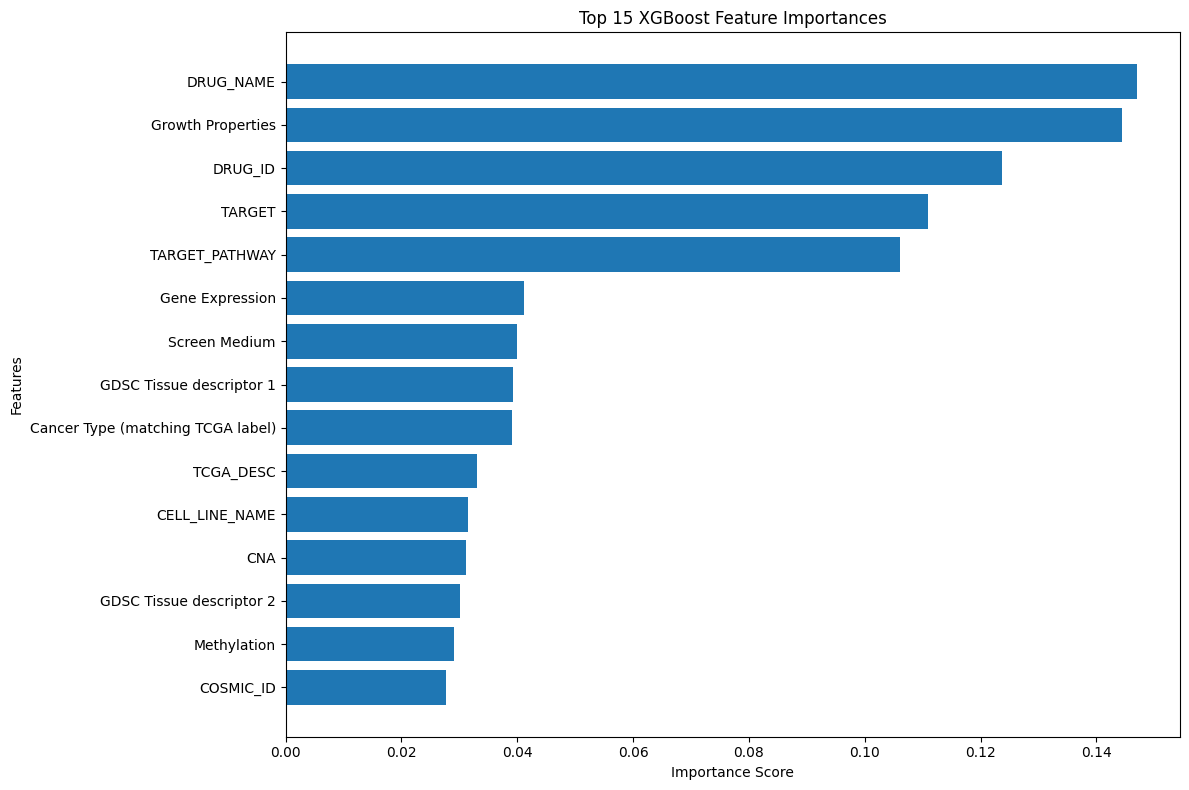

In [ ]:
# ============================================================
# STEP 12: XGBoost Feature Importance Analysis
# Purpose:
# Identify the most important biomedical features influencing
# drug sensitivity and resistance prediction.
#
# This improves interpretability of the AI-assisted framework.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 12.1 Extract feature importance values
# ------------------------------------------------------------

feature_importance = pd.DataFrame({
    "Feature": X_train_encoded.columns,
    "Importance": xgb_model.feature_importances_
})

# ------------------------------------------------------------
# 12.2 Sort features by importance
# ------------------------------------------------------------

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# ------------------------------------------------------------
# 12.3 Display top important features
# ------------------------------------------------------------

print("Top 15 Important Features:\n")

display(feature_importance.head(15))

# ------------------------------------------------------------
# 12.4 Plot feature importance
# ------------------------------------------------------------

plt.figure(figsize=(12, 8))

plt.barh(
    feature_importance["Feature"].head(15)[::-1],
    feature_importance["Importance"].head(15)[::-1]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

Comparative Model Performance:



,Model,Accuracy,F1_Score,ROC_AUC
0,Random Forest,0.828165,0.828974,0.912603
1,XGBoost,0.853389,0.853818,0.936786
2,SVM,0.623649,0.594994,0.667479
3,ANN,0.776293,0.786793,0.866862


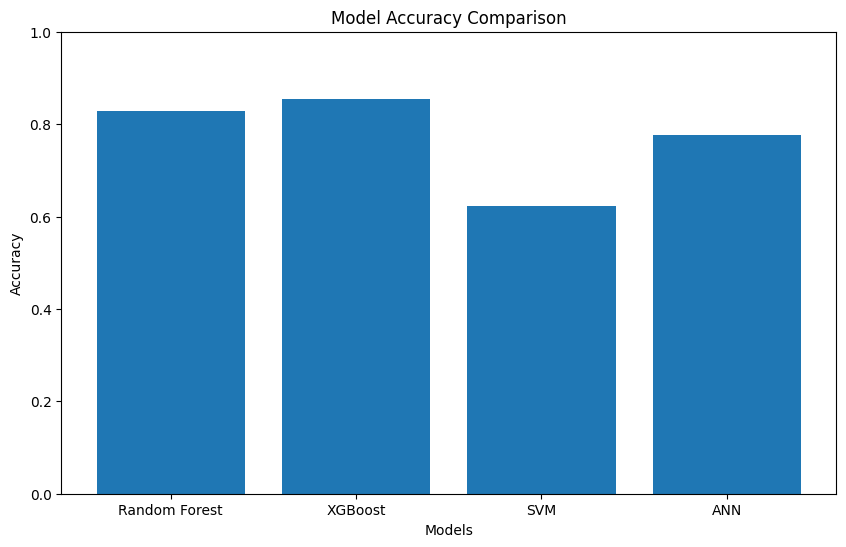

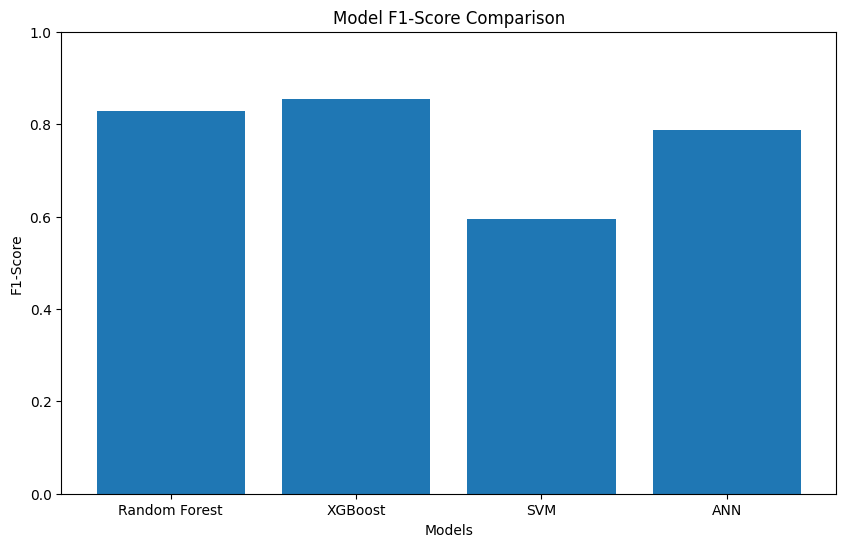

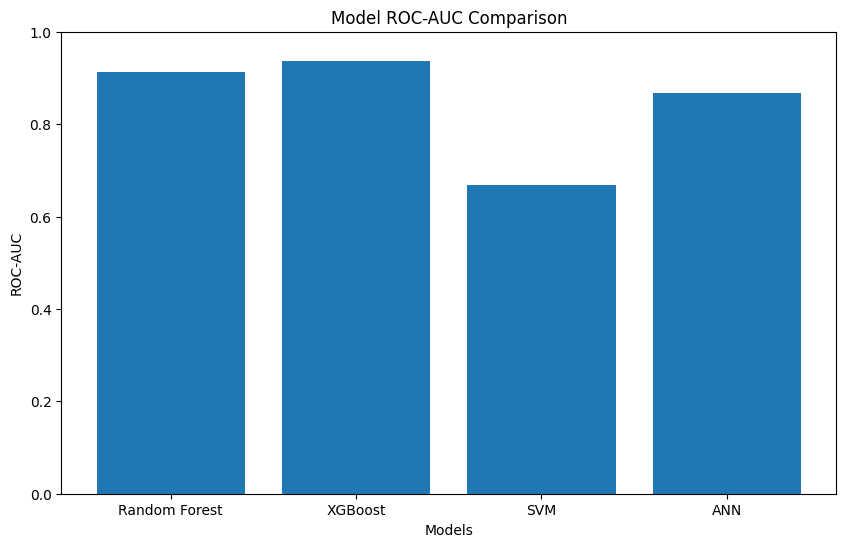

In [ ]:
# ============================================================
# STEP 13: Comparative Model Performance Visualization
# Purpose:
# Compare the performance of all ML/DL models using:
# - Accuracy
# - F1-score
# - ROC-AUC
#
# This helps identify the best predictive model for
# AI-assisted Organ-on-a-Chip drug screening systems.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 13.1 Create performance comparison table
# ------------------------------------------------------------

results_df = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost",
        "SVM",
        "ANN"
    ],

    "Accuracy": [
        rf_accuracy,
        xgb_accuracy,
        svm_accuracy,
        ann_accuracy
    ],

    "F1_Score": [
        rf_f1,
        xgb_f1,
        svm_f1,
        ann_f1
    ],

    "ROC_AUC": [
        rf_auc,
        xgb_auc,
        svm_auc,
        ann_auc
    ]
})

# ------------------------------------------------------------
# 13.2 Display results table
# ------------------------------------------------------------

print("Comparative Model Performance:\n")

display(results_df)

# ------------------------------------------------------------
# 13.3 Plot Accuracy comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Models")
plt.title("Model Accuracy Comparison")

plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# 13.4 Plot F1-score comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["F1_Score"]
)

plt.ylabel("F1-Score")
plt.xlabel("Models")
plt.title("Model F1-Score Comparison")

plt.ylim(0, 1)

plt.show()

# ------------------------------------------------------------
# 13.5 Plot ROC-AUC comparison
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

plt.bar(
    results_df["Model"],
    results_df["ROC_AUC"]
)

plt.ylabel("ROC-AUC")
plt.xlabel("Models")
plt.title("Model ROC-AUC Comparison")

plt.ylim(0, 1)

plt.show()

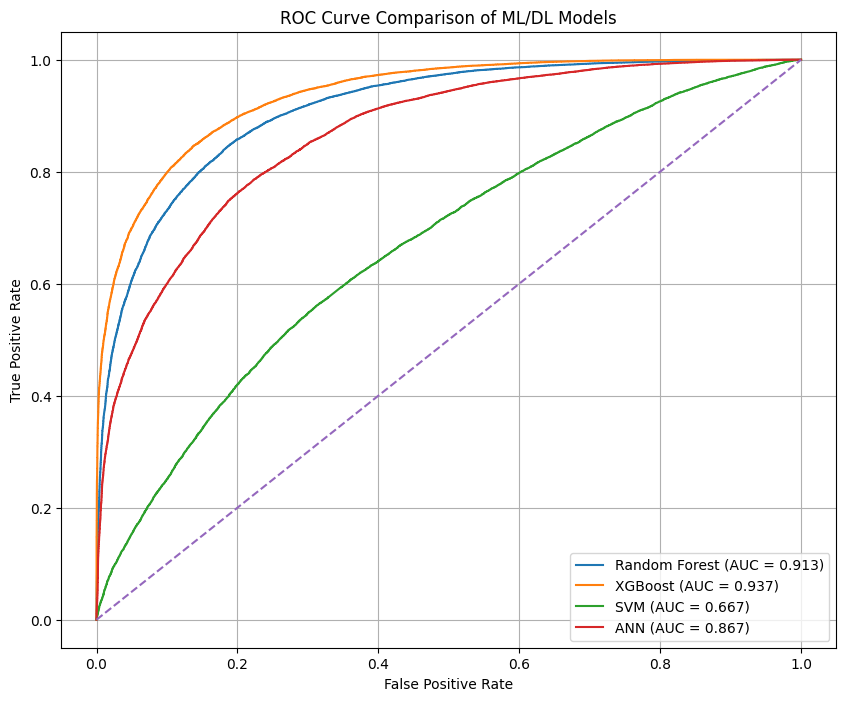

In [ ]:
# ============================================================
# STEP 14: ROC Curve Visualization
# Purpose:
# Compare ROC curves of all ML/DL models for evaluating
# discriminative performance in drug-response prediction.
# ============================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 14.1 Calculate ROC curve for Random Forest
# ------------------------------------------------------------

fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

# ------------------------------------------------------------
# 14.2 Calculate ROC curve for XGBoost
# ------------------------------------------------------------

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
roc_auc_xgb = auc(fpr_xgb, tpr_xgb)

# ------------------------------------------------------------
# 14.3 Calculate ROC curve for SVM
# ------------------------------------------------------------

fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
roc_auc_svm = auc(fpr_svm, tpr_svm)

# ------------------------------------------------------------
# 14.4 Calculate ROC curve for ANN
# ------------------------------------------------------------

fpr_ann, tpr_ann, _ = roc_curve(y_test, y_prob_ann)
roc_auc_ann = auc(fpr_ann, tpr_ann)

# ------------------------------------------------------------
# 14.5 Plot ROC curves
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

# Random Forest
plt.plot(
    fpr_rf,
    tpr_rf,
    label=f'Random Forest (AUC = {roc_auc_rf:.3f})'
)

# XGBoost
plt.plot(
    fpr_xgb,
    tpr_xgb,
    label=f'XGBoost (AUC = {roc_auc_xgb:.3f})'
)

# SVM
plt.plot(
    fpr_svm,
    tpr_svm,
    label=f'SVM (AUC = {roc_auc_svm:.3f})'
)

# ANN
plt.plot(
    fpr_ann,
    tpr_ann,
    label=f'ANN (AUC = {roc_auc_ann:.3f})'
)

# Random guess line
plt.plot([0, 1], [0, 1], linestyle='--')

# ------------------------------------------------------------
# 14.6 Figure formatting
# ------------------------------------------------------------

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of ML/DL Models")

plt.legend(loc="lower right")

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# STEP 15: Show Drug Sensitivity Prediction Examples
# Purpose:
# Use the best trained model (XGBoost) to show actual prediction
# outputs on test samples.
#
# Output:
# 0 = Resistant
# 1 = Sensitive
# ============================================================

# ------------------------------------------------------------
# 15.1 Predict class and probability using XGBoost
# ------------------------------------------------------------

sample_predictions = X_test.copy()

sample_predictions["Actual_Class"] = y_test.values
sample_predictions["Predicted_Class"] = y_pred_xgb
sample_predictions["Sensitive_Probability"] = y_prob_xgb

# ------------------------------------------------------------
# 15.2 Convert numeric labels into readable labels
# ------------------------------------------------------------

sample_predictions["Actual_Label"] = sample_predictions["Actual_Class"].map({
    1: "Sensitive",
    0: "Resistant"
})

sample_predictions["Predicted_Label"] = sample_predictions["Predicted_Class"].map({
    1: "Sensitive",
    0: "Resistant"
})

# ------------------------------------------------------------
# 15.3 Select important columns for display
# ------------------------------------------------------------

prediction_output = sample_predictions[
    [
        "DRUG_NAME",
        "CELL_LINE_NAME",
        "TCGA_DESC",
        "TARGET",
        "TARGET_PATHWAY",
        "Actual_Label",
        "Predicted_Label",
        "Sensitive_Probability"
    ]
]

# ------------------------------------------------------------
# 15.4 Show first 20 prediction examples
# ------------------------------------------------------------

prediction_output.head(20)

,DRUG_NAME,CELL_LINE_NAME,TCGA_DESC,TARGET,TARGET_PATHWAY,Actual_Label,Predicted_Label,Sensitive_Probability
119092,ML323,HCC-366,UNCLASSIFIED,"USP1, UAF1",Protein stability and degradation,Resistant,Resistant,0.049979
2003,Cisplatin,LAMA-84,LCML,DNA crosslinker,DNA replication,Sensitive,Sensitive,0.933521
197034,P22077,Caov-4,OV,"USP7, USP47",Protein stability and degradation,Sensitive,Resistant,0.208121
182075,AGI-5198,NCI-H929,MM,IDH1 (R132H),Metabolism,Resistant,Resistant,0.347530
106897,LGK974,KP-4,PAAD,PORCN,WNT signaling,Resistant,Resistant,0.118265
128547,IRAK4_4710,SW626,OV,IRAK4,"Other, kinases",Resistant,Resistant,0.034921
171806,LY2109761,MOLP-8,MM,TGFB1,Other,Resistant,Resistant,0.128926
54416,Irinotecan,HOP-92,UNCLASSIFIED,TOP1,DNA replication,Resistant,Sensitive,0.527886
118475,ML323,NCI-H1092,SCLC,"USP1, UAF1",Protein stability and degradation,Resistant,Resistant,0.027872
236303,GSK2830371,HL-60,LAML,WIP1,Other,Resistant,Resistant,0.215507


In [ ]:
# ============================================================
# STEP 16: Secondary Prediction - LN_IC50 Regression
# Purpose:
# After predicting Sensitive/Resistant classes, we now predict
# the exact continuous drug response score: LN_IC50.
#
# Lower LN_IC50 = higher drug sensitivity
# Higher LN_IC50 = higher drug resistance
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
import numpy as np

# ------------------------------------------------------------
# 16.1 Define regression target
# ------------------------------------------------------------

X_reg = data[feature_columns]
y_reg = data["LN_IC50"]

# ------------------------------------------------------------
# 16.2 Encode categorical features again for regression
# ------------------------------------------------------------

X_reg_encoded = X_reg.copy()

for col in X_reg_encoded.select_dtypes(include=["object"]).columns:
    le = LabelEncoder()
    X_reg_encoded[col] = le.fit_transform(X_reg_encoded[col].astype(str))

# ------------------------------------------------------------
# 16.3 Train-test split for regression
# ------------------------------------------------------------

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg_encoded,
    y_reg,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# 16.4 Scale regression features
# ------------------------------------------------------------

reg_scaler = StandardScaler()

X_reg_train_scaled = reg_scaler.fit_transform(X_reg_train)
X_reg_test_scaled = reg_scaler.transform(X_reg_test)

print("Regression training shape:", X_reg_train_scaled.shape)
print("Regression testing shape:", X_reg_test_scaled.shape)

Regression training shape: (193628, 16)
Regression testing shape: (48407, 16)


In [ ]:
# ============================================================
# STEP 17: Random Forest Regressor
# Purpose:
# Predict continuous LN_IC50 drug response scores.
#
# Evaluation Metrics:
# - MAE
# - RMSE
# - R² Score
# ============================================================

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# ------------------------------------------------------------
# 17.1 Initialize Random Forest Regressor
# ------------------------------------------------------------

rf_regressor = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 17.2 Train model
# ------------------------------------------------------------

print("Training Random Forest Regressor...")

rf_regressor.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Training completed.")

# ------------------------------------------------------------
# 17.3 Predict on test data
# ------------------------------------------------------------

y_pred_rf_reg = rf_regressor.predict(
    X_reg_test_scaled
)

# ------------------------------------------------------------
# 17.4 Evaluate regression performance
# ------------------------------------------------------------

rf_mae = mean_absolute_error(
    y_reg_test,
    y_pred_rf_reg
)

rf_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_pred_rf_reg
    )
)

rf_r2 = r2_score(
    y_reg_test,
    y_pred_rf_reg
)

# ------------------------------------------------------------
# 17.5 Print results
# ------------------------------------------------------------

print("\n========== Random Forest Regression Results ==========")

print(f"MAE   : {rf_mae:.4f}")
print(f"RMSE  : {rf_rmse:.4f}")
print(f"R²    : {rf_r2:.4f}")

Training Random Forest Regressor...
Training completed.

========== Random Forest Regression Results ==========
MAE   : 0.9590
RMSE  : 1.2813
R²    : 0.7848


In [ ]:
# ============================================================
# STEP 18: XGBoost Regressor
# Purpose:
# Predict continuous LN_IC50 drug-response scores using
# gradient boosting regression.
#
# Expected:
# Better regression performance than Random Forest.
# ============================================================

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

# ------------------------------------------------------------
# 18.1 Initialize XGBoost Regressor
# ------------------------------------------------------------

xgb_regressor = XGBRegressor(
    n_estimators=200,
    max_depth=10,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='reg:squarederror',
    random_state=42,
    n_jobs=-1
)

# ------------------------------------------------------------
# 18.2 Train model
# ------------------------------------------------------------

print("Training XGBoost Regressor...")

xgb_regressor.fit(
    X_reg_train_scaled,
    y_reg_train
)

print("Training completed.")

# ------------------------------------------------------------
# 18.3 Predict on test data
# ------------------------------------------------------------

y_pred_xgb_reg = xgb_regressor.predict(
    X_reg_test_scaled
)

# ------------------------------------------------------------
# 18.4 Evaluate regression performance
# ------------------------------------------------------------

xgb_mae = mean_absolute_error(
    y_reg_test,
    y_pred_xgb_reg
)

xgb_rmse = np.sqrt(
    mean_squared_error(
        y_reg_test,
        y_pred_xgb_reg
    )
)

xgb_r2 = r2_score(
    y_reg_test,
    y_pred_xgb_reg
)

# ------------------------------------------------------------
# 18.5 Print results
# ------------------------------------------------------------

print("\n========== XGBoost Regression Results ==========")

print(f"MAE   : {xgb_mae:.4f}")
print(f"RMSE  : {xgb_rmse:.4f}")
print(f"R²    : {xgb_r2:.4f}")

Training XGBoost Regressor...
Training completed.

========== XGBoost Regression Results ==========
MAE   : 0.8076
RMSE  : 1.0822
R²    : 0.8465


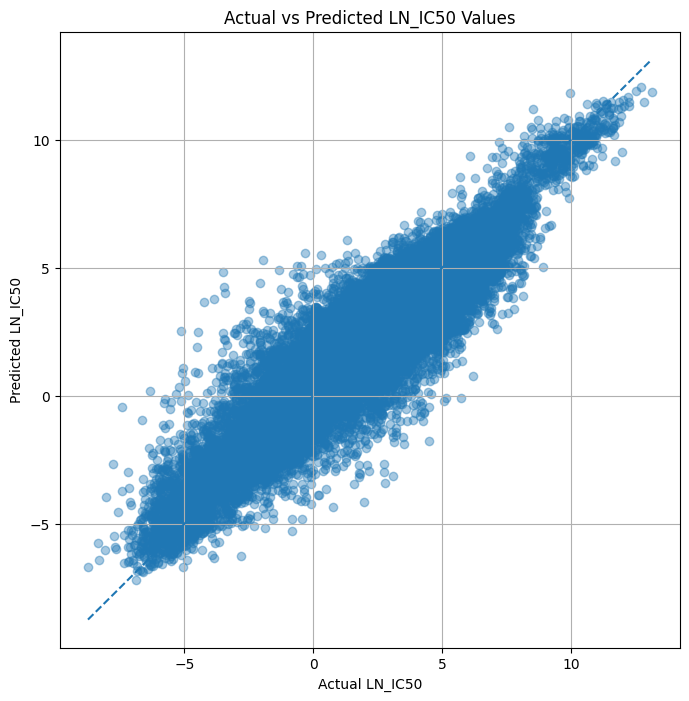

In [ ]:
# ============================================================
# STEP 19: Regression Prediction Visualization
# Purpose:
# Visualize actual vs predicted LN_IC50 values using the
# best regression model (XGBoost Regressor).
#
# This helps evaluate how closely the predicted drug-response
# scores match the actual biomedical response values.
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 19.1 Create scatter plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 8))

plt.scatter(
    y_reg_test,
    y_pred_xgb_reg,
    alpha=0.4
)

# ------------------------------------------------------------
# 19.2 Add ideal prediction line
# Purpose:
# Perfect predictions should lie close to this diagonal line.
# ------------------------------------------------------------

min_val = min(y_reg_test.min(), y_pred_xgb_reg.min())
max_val = max(y_reg_test.max(), y_pred_xgb_reg.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle='--'
)

# ------------------------------------------------------------
# 19.3 Figure formatting
# ------------------------------------------------------------

plt.xlabel("Actual LN_IC50")
plt.ylabel("Predicted LN_IC50")

plt.title("Actual vs Predicted LN_IC50 Values")

plt.grid(True)

plt.show()

In [ ]:
# ============================================================
# STEP 20B: Create readable Future OoC Integration Output
# Purpose:
# Display final simulated OoC prediction results with original
# readable drug names, cell line names, cancer type, targets,
# predicted class, predicted LN_IC50, and AI recommendation.
# ============================================================

# Use original readable test data
ooc_readable_output = X_test.copy()

# Add actual and predicted outputs
ooc_readable_output["Actual_LN_IC50"] = y_reg_test.values
ooc_readable_output["Predicted_LN_IC50"] = ooc_predicted_ln_ic50
ooc_readable_output["Predicted_Response"] = ooc_class_prediction
ooc_readable_output["Sensitive_Probability"] = ooc_sensitive_probability

# Convert numeric response to readable label
ooc_readable_output["Predicted_Response"] = ooc_readable_output["Predicted_Response"].map({
    1: "Sensitive",
    0: "Resistant"
})

# Add recommendation
ooc_readable_output["AI_OoC_Recommendation"] = ooc_readable_output.apply(
    drug_recommendation,
    axis=1
)

# Select paper-ready columns
final_ooc_output = ooc_readable_output[
    [
        "DRUG_NAME",
        "CELL_LINE_NAME",
        "TCGA_DESC",
        "TARGET",
        "TARGET_PATHWAY",
        "Actual_LN_IC50",
        "Predicted_LN_IC50",
        "Predicted_Response",
        "Sensitive_Probability",
        "AI_OoC_Recommendation"
    ]
]

final_ooc_output.head(20)

,DRUG_NAME,CELL_LINE_NAME,TCGA_DESC,TARGET,TARGET_PATHWAY,Actual_LN_IC50,Predicted_LN_IC50,Predicted_Response,Sensitive_Probability,AI_OoC_Recommendation
119092,ML323,HCC-366,UNCLASSIFIED,"USP1, UAF1",Protein stability and degradation,0.277583,0.413823,Sensitive,0.687365,Moderate-priority candidate for OoC validation
2003,Cisplatin,LAMA-84,LCML,DNA crosslinker,DNA replication,0.538679,0.294185,Sensitive,0.934764,High-priority candidate for OoC validation
197034,P22077,Caov-4,OV,"USP7, USP47",Protein stability and degradation,3.113238,3.255989,Sensitive,0.549651,Uncertain response; requires further OoC testing
182075,AGI-5198,NCI-H929,MM,IDH1 (R132H),Metabolism,2.373758,1.520246,Sensitive,0.711058,Moderate-priority candidate for OoC validation
106897,LGK974,KP-4,PAAD,PORCN,WNT signaling,-0.919956,-0.770067,Sensitive,0.981553,High-priority candidate for OoC validation
128547,IRAK4_4710,SW626,OV,IRAK4,"Other, kinases",0.806657,-0.795440,Sensitive,0.857303,High-priority candidate for OoC validation
171806,LY2109761,MOLP-8,MM,TGFB1,Other,1.933458,4.414379,Resistant,0.368236,Uncertain response; requires further OoC testing
54416,Irinotecan,HOP-92,UNCLASSIFIED,TOP1,DNA replication,4.118681,5.152894,Resistant,0.043332,Low-priority / resistant response predicted
118475,ML323,NCI-H1092,SCLC,"USP1, UAF1",Protein stability and degradation,0.279877,-1.003740,Sensitive,0.969949,High-priority candidate for OoC validation
236303,GSK2830371,HL-60,LAML,WIP1,Other,4.047798,3.676370,Resistant,0.348857,Uncertain response; requires further OoC testing


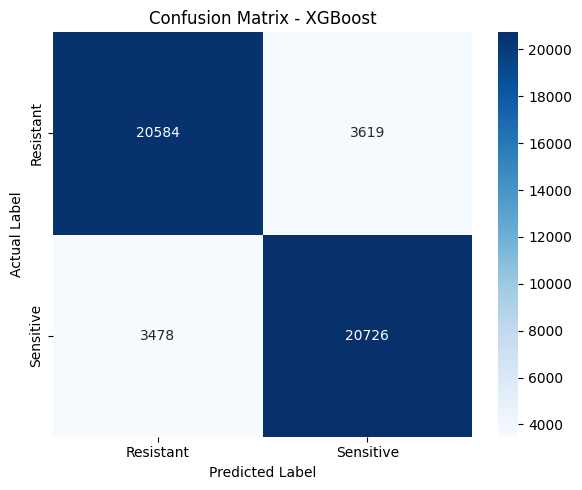

In [ ]:
# ============================================================
# STEP 21: XGBoost Confusion Matrix Heatmap
# Purpose:
# Visualize classification performance of the best model
# (XGBoost) using a confusion matrix heatmap.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 21.1 Compute confusion matrix
# ------------------------------------------------------------

cm_xgb = confusion_matrix(y_test, y_pred_xgb)

# ------------------------------------------------------------
# 21.2 Plot heatmap
# ------------------------------------------------------------

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_xgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Resistant", "Sensitive"],
    yticklabels=["Resistant", "Sensitive"]
)

# ------------------------------------------------------------
# 21.3 Figure formatting
# ------------------------------------------------------------

plt.title("Confusion Matrix - XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()

plt.show()